<a href="https://colab.research.google.com/github/carotavil-prog/ICN292-Lab3-Tavil-Carolina/blob/main/gr%C3%A1ficas%20y%20incertidumbre%20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
P = Params()

resultado = run_case(P)

print("Alcance =", resultado["R"], "m")
print("Apogeo =", resultado["z_max"], "m")

Alcance = 6.336743326262225e-15 m
Apogeo = 42.487755108505695 m


In [17]:
# ==========================================================
# Sensibilidad del APOGEO (+5% en cada parámetro)
# ==========================================================

import pandas as pd

# Caso nominal
P0 = Params()
res0 = run_case(P0)

H0 = res0["z_max"]

print(f"Apogeo nominal = {H0:.4f} m")

# Parámetros a estudiar
casos = {
    "CD": Params(CD=P0.CD * 1.05),
    "Masa seca": Params(m_seco=P0.m_seco * 1.05),
    "Presión inicial": Params(p_man=P0.p_man * 1.05),
    "Fracción de agua": Params(phi=P0.phi * 1.05),
}

resultados = []

for nombre, P_mod in casos.items():

    res = run_case(P_mod)

    H = res["z_max"]

    # valor nominal del parámetro
    if nombre == "CD":
        X = P0.CD

    elif nombre == "Masa seca":
        X = P0.m_seco

    elif nombre == "Presión inicial":
        X = P0.p_man

    elif nombre == "Fracción de agua":
        X = P0.phi

    dX = 0.05 * X

    # derivada numérica
    derivada = (H - H0) / dX

    # sensibilidad normalizada
    S = derivada * X / H0

    resultados.append({
        "Parámetro": nombre,
        "Valor nominal": X,
        "Valor +5%": 1.05 * X,
        "Apogeo nominal (m)": H0,
        "Apogeo con +5% (m)": H,
        "Derivada numérica": derivada,
        "Sensibilidad normalizada": S
    })

tabla_apogeo = pd.DataFrame(resultados)

print("\nRESULTADOS")
display(tabla_apogeo.round(4))

Apogeo nominal = 42.4878 m

RESULTADOS


,Parámetro,Valor nominal,Valor +5%,Apogeo nominal (m),Apogeo con +5% (m),Derivada numérica,Sensibilidad normalizada
0,CD,0.5000,0.5250,42.4878,41.2074,-51.2143,-0.6027
1,Masa seca,0.0540,0.0567,42.4878,42.9972,188.6779,0.2398
2,Presión inicial,400000.0000,420000.0000,42.4878,43.6796,0.0001,0.5610
3,Fracción de agua,0.3333,0.3500,42.4878,42.0940,-23.6231,-0.1853


In [18]:
P_theta = Params(theta0_deg=89.0)

res_theta = run_case(P_theta)

H_theta = res_theta["z_max"]

deriv_theta = (H_theta - H0) / (89 - 90)

S_theta = deriv_theta * 90 / H0

print("Apogeo con θ = 89° =", H_theta)
print("dH/dθ =", deriv_theta)
print("Sensibilidad =", S_theta)

Apogeo con θ = 89° = 42.47705247515976
dH/dθ = 0.010702633345935908
Sensibilidad = 0.022670931864352598


In [19]:
res = run_case(P)

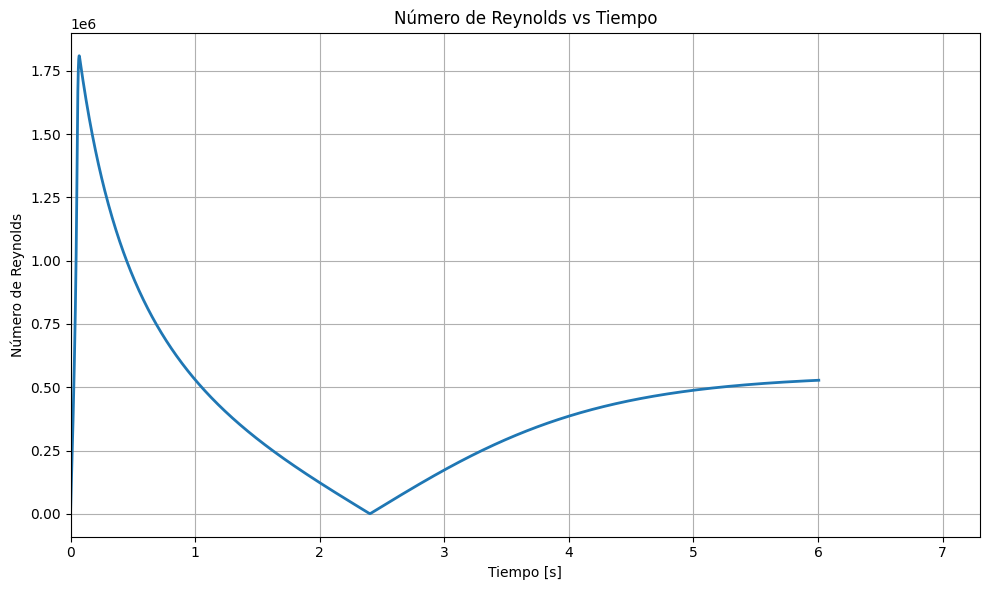

In [20]:
import matplotlib.pyplot as plt

t = res['t']
Re = res['Re']

plt.figure(figsize=(10,6))
plt.plot(t, Re, linewidth=2)

plt.xlabel('Tiempo [s]')
plt.ylabel('Número de Reynolds')
plt.title('Número de Reynolds vs Tiempo')
plt.grid(True)

plt.xlim(0, 7.3)

plt.tight_layout()
plt.show()

In [21]:
import pandas as pd

df = pd.DataFrame({
    'Tiempo (s)': res['t'],
    'Reynolds': res['Re']
})

df.to_excel('Reynolds_vs_Tiempo.xlsx', index=False)

In [22]:
V = np.sqrt(
    (res['vx'] - P.U_inf)**2 +
    res['vz']**2
)

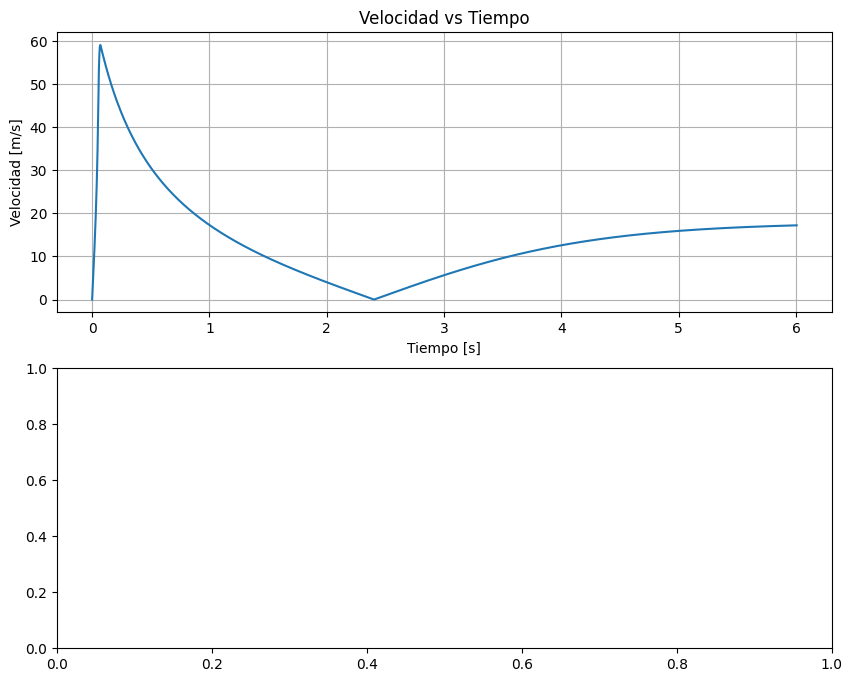

In [26]:
fig, ax = plt.subplots(2,1, figsize=(10,8))

ax[0].plot(res['t'], V)
ax[0].set_ylabel('Velocidad [m/s]')
ax[0].set_xlabel('Tiempo [s]')
ax[0].set_title('Velocidad vs Tiempo')
ax[0].grid()

plt.show()

In [33]:
import numpy as np

Re = res['Re']

Pr = 0.714

Nu = np.zeros(len(Re))

for i in range(len(Re)):

    if Re[i] < 5e5:
        Nu[i] = 0.664*np.sqrt(Re[i])*Pr**(1/3)

    else:
        Nu[i] = (0.037*Re[i]**0.8 - 871)*Pr**(1/3)

In [34]:
k_air = 0.02525
L_ref = 0.45

h_ext = Nu*k_air/L_ref


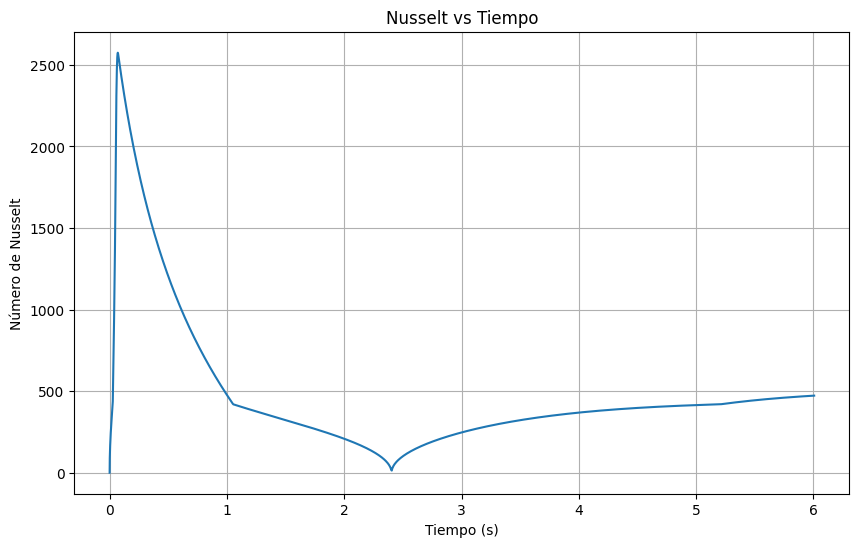

In [35]:
plt.figure(figsize=(10,6))
plt.plot(res['t'], res['Nu'])

plt.xlabel('Tiempo (s)')
plt.ylabel('Número de Nusselt')
plt.title('Nusselt vs Tiempo')
plt.grid(True)

plt.show()

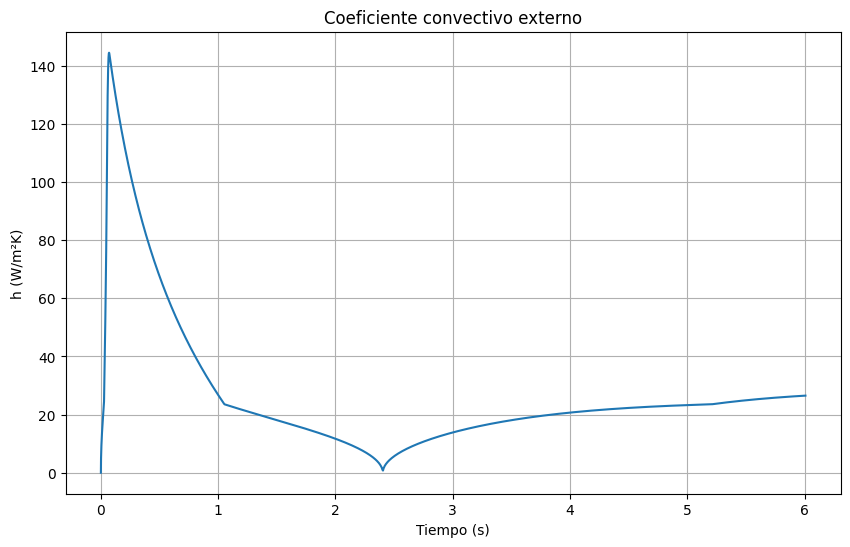

In [36]:
plt.figure(figsize=(10,6))
plt.plot(res['t'], res['h_ext'])

plt.xlabel('Tiempo (s)')
plt.ylabel('h (W/m²K)')
plt.title('Coeficiente convectivo externo')
plt.grid(True)

plt.show()

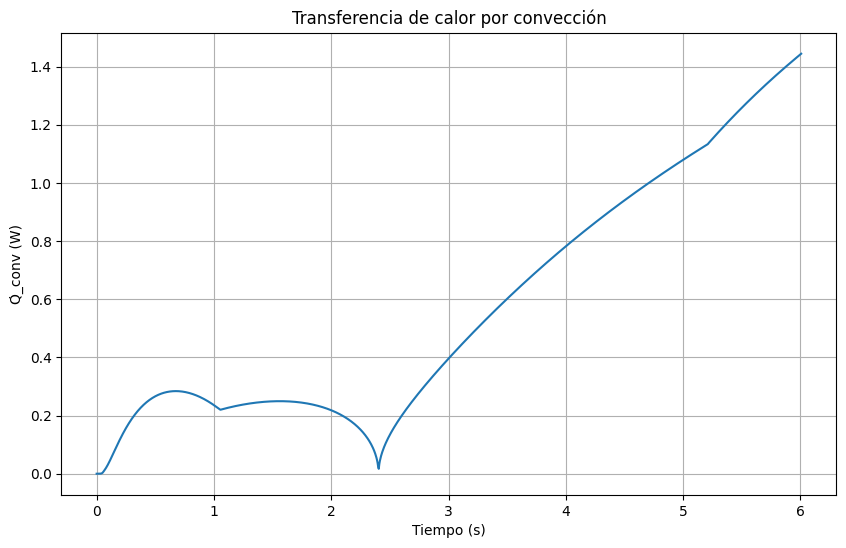

In [37]:
import matplotlib.pyplot as plt

Q_conv = res['h_ext'] * P.A_w * (P.T_inf - res['Tw'][:,0])

plt.figure(figsize=(10,6))
plt.plot(res['t'], Q_conv)

plt.xlabel('Tiempo (s)')
plt.ylabel('Q̇_conv (W)')
plt.title('Transferencia de calor por convección')
plt.grid(True)

plt.show()